# Three resolutions of one temperature slice

`NVB_C009_z42_temperature_xz` at 512², 1024² and 2048². The notebook shows the log10 field at each resolution, **checks whether the three files are the same region**, and shows the zones the website's AMR-style ASCII art refines and how the levels map onto 16 ASCII levels.

Set `DATA` below if the files live elsewhere.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

DATA = Path.home() / 'Downloads'
FILES = {512: 'NVB_C009_n0512_z42_temperature_xz_y256.f32',
         1024: 'NVB_C009_n1024_z42_temperature_xz_y512.f32',
         2048: 'NVB_C009_n2048_z42_temperature_xz_y1024.f32'}

raw = {n: np.fromfile(DATA / f, dtype='<f4').reshape(n, n) for n, f in FILES.items()}
L = {n: np.log10(a) for n, a in raw.items()}          # log transform: a few hot filaments dominate the linear field
for n, a in raw.items():
    print(f'{n:>4}^2  min {a.min():9.1f}  median {np.median(a):9.1f}  max {a.max():9.1f}  (log10 {L[n].min():.2f} .. {L[n].max():.2f})')

 512^2  min    2443.8  median    6061.0  max  106458.1  (log10 3.39 .. 5.03)
1024^2  min    2287.9  median    6214.6  max 1822560.6  (log10 3.36 .. 6.26)
2048^2  min    2197.8  median    6158.8  max 7457891.0  (log10 3.34 .. 6.87)


## 1. The three resolutions, side by side

One shared colour scale (the 1st to 99.7th percentile of the 512² log field), so the levels are directly comparable.

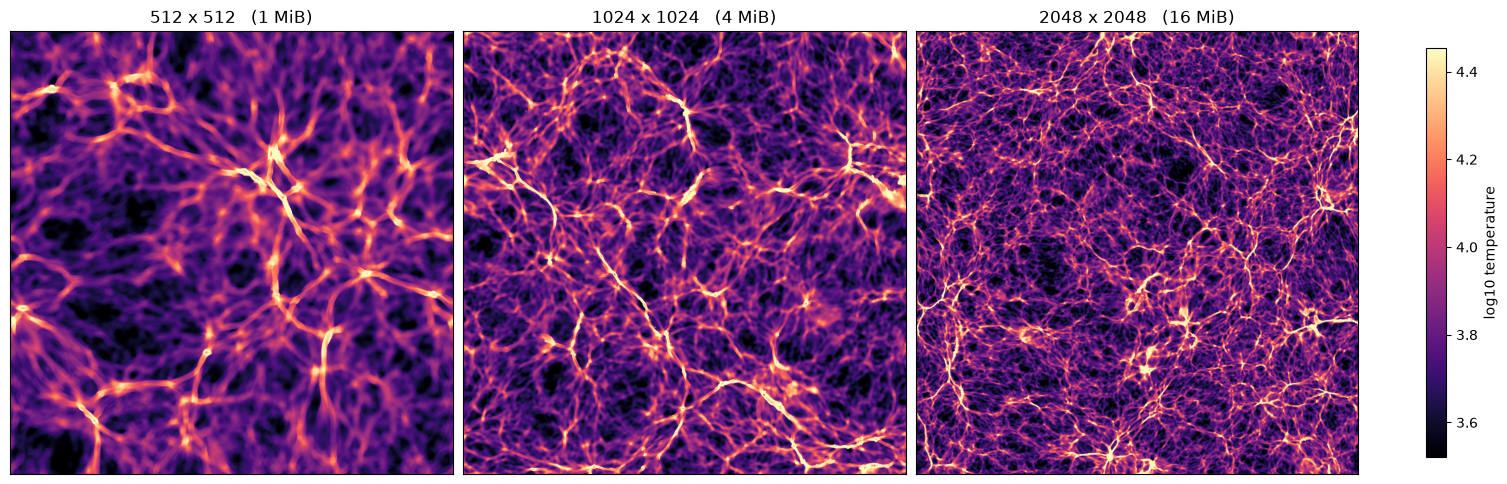

In [2]:
lo, hi = np.percentile(L[512], [1, 99.7])
fig, axes = plt.subplots(1, 3, figsize=(15, 5.2), constrained_layout=True)
for ax, n in zip(axes, FILES):
    im = ax.imshow(L[n], cmap='magma', vmin=lo, vmax=hi, origin='upper')
    ax.set_title(f'{n} x {n}   ({raw[n].nbytes / 2**20:.0f} MiB)')
    ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(im, ax=axes, shrink=.8, label='log10 temperature')
plt.show()

## 2. Are the three files the same region?

If the finer files were refinements of the coarse one, block-averaging them down to 512² would reproduce it. Here they do not: the correlation is near zero, and a full cross-correlation over every shift, flip and transpose finds nothing above noise. The three files are statistically alike (same texture, same filament network) but are **independent samples**, not nested refinements of one domain. The finer files also resolve much hotter peaks (see the maxima above). So the AMR-style art on the page refines *by analogy*: each finer level shows the same kind of field at higher resolution, in the zone chosen on the coarse level.

In [3]:
def down(a, k):
    n = a.shape[0] // k
    return a.reshape(n, k, n, k).mean(axis=(1, 3))

def zscore(a):
    return (a - a.mean()) / a.std()

def best_xcorr(ref, v):
    """Largest circular cross-correlation of v with ref over every shift, flip and transpose."""
    out = []
    for flip_y in (False, True):
        for flip_x in (False, True):
            for tr in (False, True):
                w = v[::-1] if flip_y else v
                w = w[:, ::-1] if flip_x else w
                w = w.T if tr else w
                f = np.fft.ifft2(np.fft.fft2(ref) * np.conj(np.fft.fft2(w))).real / ref.size
                out.append(f.max())
    return max(out)

ref = zscore(L[512])
for n, k in ((1024, 2), (2048, 4)):
    v = np.log10(down(raw[n], k))
    r = np.corrcoef(v.ravel(), L[512].ravel())[0, 1]
    print(f'{n}^2 block-mean vs 512^2: direct corr {r:+.3f}; best over shifts/flips {best_xcorr(ref, zscore(v)):.3f}')

1024^2 block-mean vs 512^2: direct corr -0.006; best over shifts/flips 0.131
2048^2 block-mean vs 512^2: direct corr -0.012; best over shifts/flips 0.089


## 3. Why log?

The linear field is dominated by a few hot filaments; the log field spreads the structure across the whole range. The histogram shows how skewed the values are.

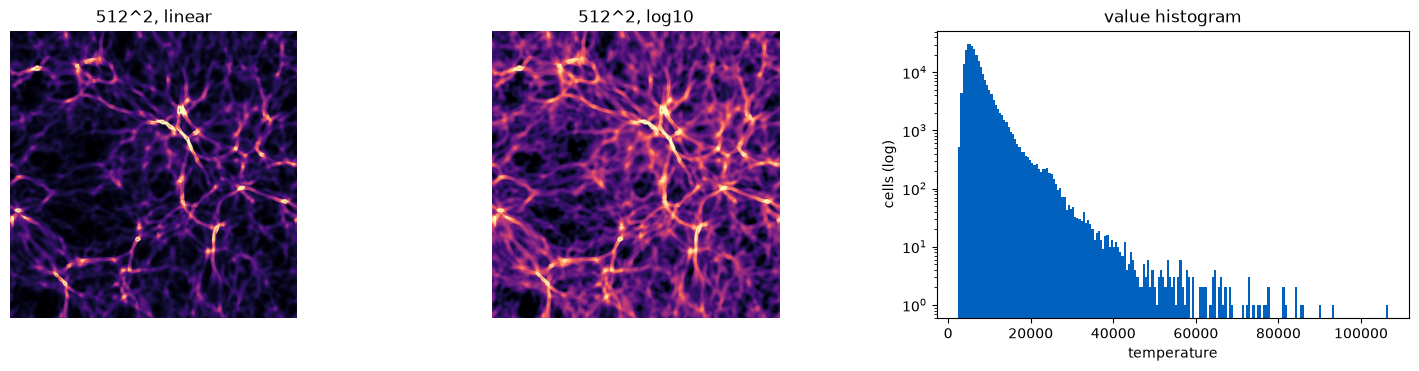

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), constrained_layout=True)
a = raw[512]
axes[0].imshow(np.clip(a, *np.percentile(a, [1, 99.7])), cmap='magma'); axes[0].set_title('512^2, linear'); axes[0].axis('off')
axes[1].imshow(L[512], cmap='magma', vmin=lo, vmax=hi); axes[1].set_title('512^2, log10'); axes[1].axis('off')
axes[2].hist(a.ravel(), bins=200, log=True, color='#0061bf')
axes[2].set_xlabel('temperature'); axes[2].set_ylabel('cells (log)'); axes[2].set_title('value histogram')
plt.show()

## 4. Choosing the refinement zones

The website's art uses a 16:9 band of the slice, averaged onto a 64x36 base grid. The densest 22x12-cell window of that grid (highest total log temperature) is refined with the 1024 data, and the densest half of that window is refined again with the 2048 data.

In [5]:
BAND_Y0, BAND_H = 90, 288          # rows of the 512 slice
COLS, ROWS = 64, 36                # base grid, 8x8 source cells each
WC, WR = 22, 12                    # patch-1 window, in base cells

def blocks(a, rows, cols):
    h, w = a.shape
    return a[: h // rows * rows, : w // cols * cols].reshape(rows, h // rows, cols, w // cols).mean(axis=(1, 3))

def best_window(g, wr, wc):
    ii = np.pad(g, ((1, 0), (1, 0))).cumsum(0).cumsum(1)
    best = (-np.inf, 0, 0)
    for r in range(g.shape[0] - wr + 1):
        for c in range(g.shape[1] - wc + 1):
            s = ii[r + wr, c + wc] - ii[r, c + wc] - ii[r + wr, c] + ii[r, c]
            if s > best[0]:
                best = (s, r, c)
    return best[1:]

base = blocks(L[512][BAND_Y0:BAND_Y0 + BAND_H], ROWS, COLS)
r0, c0 = best_window(base, WR, WC)

# patch 1 from the 1024 data (2x the 512 resolution), averaged to 3 samples per base cell
p1 = blocks(L[1024][(BAND_Y0 + r0 * 8) * 2:(BAND_Y0 + (r0 + WR) * 8) * 2, c0 * 16:(c0 + WC) * 16], WR * 3, WC * 3)
# patch 2: the densest half of patch 1, from the 2048 data (4x)
wr2, wc2 = WR * 3 // 2, WC * 3 // 2
r1, c1 = best_window(p1, wr2, wc2)
y2 = BAND_Y0 * 4 + int(round((r0 * 8 + r1 / 3 * 8) * 4)); x2 = int(round((c0 * 8 + c1 / 3 * 8) * 4))
h2, w2 = int(round(wr2 / 3 * 8 * 4)), int(round(wc2 / 3 * 8 * 4))
p2 = blocks(L[2048][y2:y2 + h2, x2:x2 + w2], 36, 66)

print('patch 1: base cells (row, col) =', (r0, c0), ' size', (WR, WC))
print('patch 2: offset inside patch 1 (row, col) =', (r1, c1))

patch 1: base cells (row, col) = (6, 31)  size (12, 22)
patch 2: offset inside patch 1 (row, col) = (10, 31)


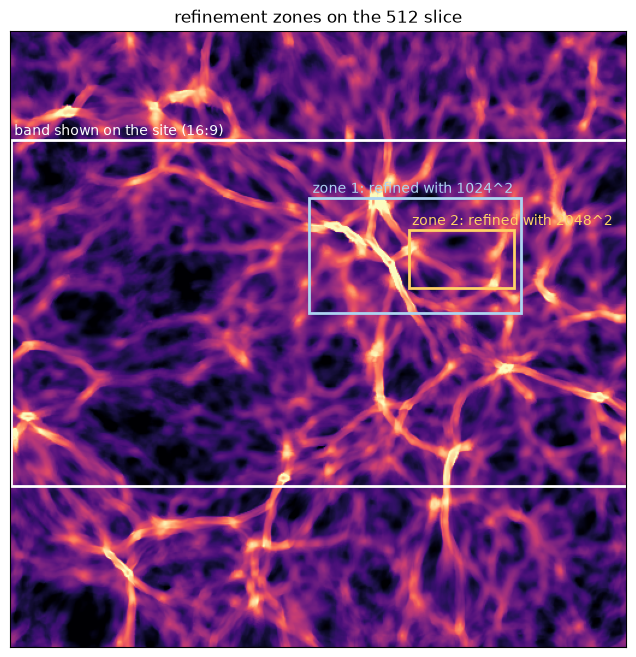

In [6]:
# where the zones sit, on the 512 slice (coordinates in 512-source pixels)
fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(L[512], cmap='magma', vmin=lo, vmax=hi)
def box(x, y, w, h, c, label):
    ax.add_patch(plt.Rectangle((x, y), w, h, fill=False, ec=c, lw=2)); ax.text(x + 3, y - 4, label, color=c, fontsize=10)
box(0, BAND_Y0, 512, BAND_H, 'white', 'band shown on the site (16:9)')
box(c0 * 8, BAND_Y0 + r0 * 8, WC * 8, WR * 8, '#add3f1', 'zone 1: refined with 1024^2')
box(x2 / 4, y2 / 4, w2 / 4, h2 / 4, '#ffd166', 'zone 2: refined with 2048^2')
ax.set_xticks([]); ax.set_yticks([]); ax.set_title('refinement zones on the 512 slice')
plt.show()

## 5. The same zone at each resolution

Zone 2 at the same normalised position in each file. Because the files are independent samples (section 2), the crops show the same *kind* of structure at three resolutions, not the same filaments.

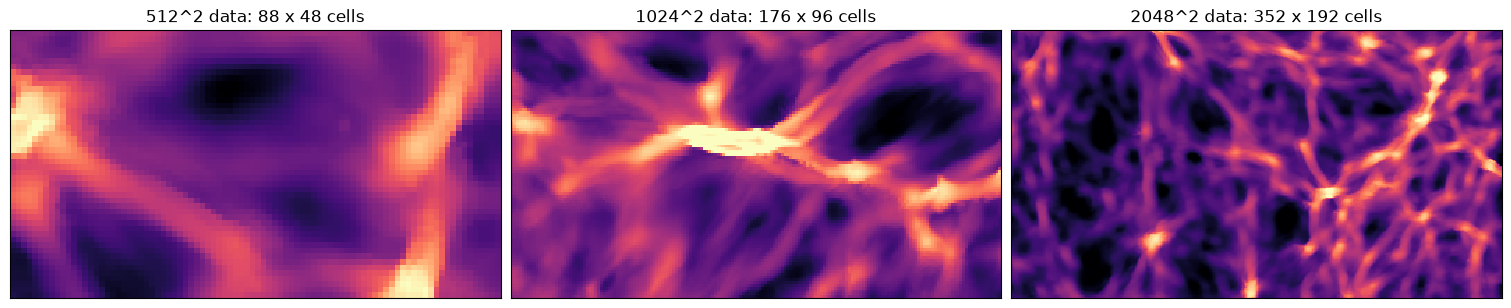

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5), constrained_layout=True)
for ax, (n, s) in zip(axes, ((512, 1), (1024, 2), (2048, 4))):
    crop = L[n][y2 // 4 * s:(y2 // 4 + h2 // 4) * s, x2 // 4 * s:(x2 // 4 + w2 // 4) * s]
    ax.imshow(crop, cmap='magma', vmin=lo, vmax=hi, interpolation='nearest')
    ax.set_title(f'{n}^2 data: {crop.shape[1]} x {crop.shape[0]} cells')
    ax.set_xticks([]); ax.set_yticks([])
plt.show()

## 6. The AMR levels as ASCII

Every level is averaged in log space onto 16 levels with one shared stretch (2nd to 99.5th percentile of the base), then drawn as characters. Fine levels use smaller cells for the same area.

In [8]:
RAMP = " .,'`-:;~+=*#%&@8"
blo, bhi = np.percentile(base, [2, 99.5])
lvl = lambda g: np.minimum((np.clip((g - blo) / (bhi - blo), 0, 1) * 16).astype(int), 15)

def ascii_art(g, step=1):
    q = lvl(g)[::step, ::step]
    return '\n'.join(''.join(RAMP[v] for v in row) for row in q)

print('base level (64 x 36):'); print(ascii_art(base)); print()
print('zone 1 (1024 data, 66 x 36):'); print(ascii_art(p1))

base level (64 x 36):
:=;,   '::~;`''==*=::~=+;::----:`,`+,'`+`'.-;``;~,.,``-~,,`:--'`
-:,. .. `,-,..,~~-;`.--:---;'`;=:.`;'`~*`,,~:`'-;''.,'`;-,`:'``,
,', ..,'``',,.,=+-'-'--;:-':+:'-;-:-'`~=,,`#'''-``..,'`:~':`,:',
.''  .,`;`..,-+=~~~+:''--:-``;``''-:,-+#:-=*',``'-..,`-:=+;'``. 
.,.   .`--:~#%+;',`:=;'''.`:'-:`..`::-*@*=~-,,`-`;`';:`-=~-:'   
``...,`-'`-~;~:`-`'--~*;',.--'';-`-`+&@==:..,--;++:~=;~~*:--'  ,
:-'''-;-'`--;~`',,'-''-;+=:-~~''~;--~@@#-,. ,-:~*~:;=+=~#-``,,,`
`-~:;;:---`'`;`''',',`-'`:;;~#+~-;;~+&@%`-`,`--:--;~#+``%*-~;:`,
'-=~:,''`````:`'``'`,''''-``-:+*##*=;#:#:--`-:`:::++*:,-#@#;=-.,
;;~-',,'--',':`''.-`,','.,``:~+%%#@&~#:;=:-~~--:;:;#=-`;;*~`~--:
``:-,..`-,.,'--`, `','`''::;~::~:`'%@@~`:#=;-. ,`-~#:`::'~:-~','
.''`,':;,,,.,`',''-'``-:;;:*~:-:++:~@#@-~@%;-'''-~%;''-;:~`'-',,
 ,`'`::',,,.,.... ..,.,'`-:=:-`-+=#=~~%@=*=+;--`-+*:`,-=+`'''',.
 '`.``''.`-',.. .    .,`;+~~--::;;=:'-`@++-`:~;'':=:-:;%~,`-```.
''.,;~--``'`,'...    ,`:-,,---=~`:+;-`:&%,`.,:=:;+&:`:**`..';:'.
..,

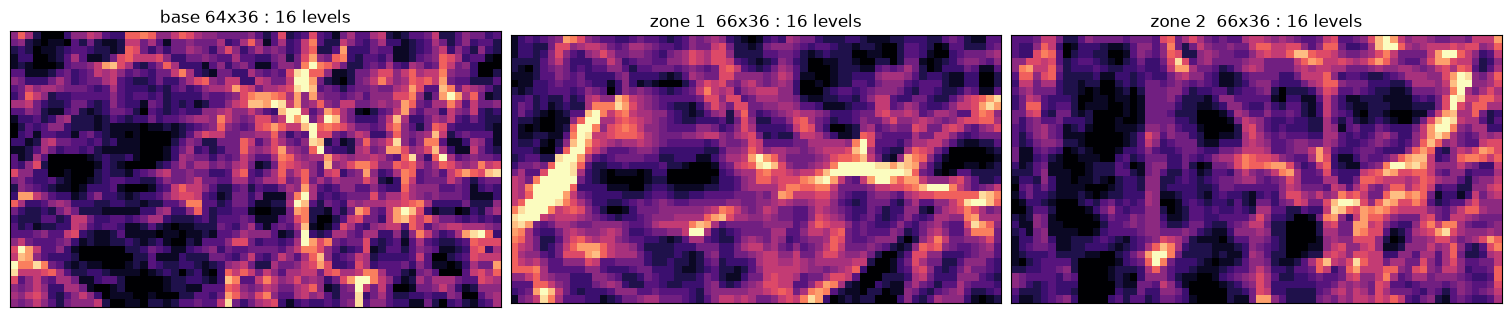

levels used, per level: [16, 16, 16]


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), constrained_layout=True)
for ax, (g, name) in zip(axes, ((base, 'base 64x36'), (p1, 'zone 1  66x36'), (p2, 'zone 2  66x36'))):
    ax.imshow(lvl(g), cmap='magma', vmin=0, vmax=15, interpolation='nearest')
    ax.set_title(name + ' : 16 levels'); ax.set_xticks([]); ax.set_yticks([])
plt.show()
print('levels used, per level:', [int(np.unique(lvl(g)).size) for g in (base, p1, p2)])